In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection"

dataset_path = os.path.join(project_path, "Dataset")

os.makedirs(dataset_path, exist_ok=True)

print("Project folder created!")
print(dataset_path)


Project folder created!
/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset


In [36]:
%cd /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset

!wget -c "https://zenodo.org/records/3678171/files/dev_data_fan.zip?download=1" -O "{zip_path}"

/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset
--2026-11-18 16:12:50--  https://zenodo.org/records/3678171/files/dev_data_fan.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.47.192, 188.185.45.63, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1354774772 (1.3G) [application/octet-stream]
Saving to: ‘{zip_path}’

{zip_path}          100%[===================>]   1.26G  3.53MB/s    in 6m 36s  

2026-11-18 16:19:26 (3.27 MB/s) - ‘{zip_path}’ saved [1354774772/1354774772]



In [4]:
import os

zip_path = os.path.join(dataset_path, "dev_data_fan.zip")

if os.path.exists(zip_path):
    size_gb = os.path.getsize(zip_path) / (1024 ** 3)

    print("Dataset downloaded successfully!")
    print("File size:", round(size_gb, 2), "GB")
else:
    print("Dataset file not found!")

Dataset downloaded successfully!
File size: 1.26 GB


In [5]:
!md5sum dev_data_fan.zip

649bdfc06263ae7a838963f43b6641e6  dev_data_fan.zip


In [6]:
import zipfile
import os

zip_path = os.path.join(dataset_path, "dev_data_fan.zip")

with zipfile.ZipFile(zip_path, 'r') as zip_file:
    result = zip_file.testzip()

    if result is None:
        print("ZIP file is valid. No corrupted files detected.")
    else:
        print("Corrupted file found:", result)

ZIP file is valid. No corrupted files detected.


In [7]:
with zipfile.ZipFile(zip_path, 'r') as zip_file:

    file_list = zip_file.namelist()

    print("Total entries:", len(file_list))

    print("\nFirst 30 entries:")

    for file in file_list[:30]:
        print(file)

Total entries: 5553

First 30 entries:
fan/
fan/test/
fan/test/anomaly_id_00_00000000.wav
fan/test/anomaly_id_00_00000001.wav
fan/test/anomaly_id_00_00000002.wav
fan/test/anomaly_id_00_00000003.wav
fan/test/anomaly_id_00_00000004.wav
fan/test/anomaly_id_00_00000005.wav
fan/test/anomaly_id_00_00000006.wav
fan/test/anomaly_id_00_00000007.wav
fan/test/anomaly_id_00_00000008.wav
fan/test/anomaly_id_00_00000009.wav
fan/test/anomaly_id_00_00000010.wav
fan/test/anomaly_id_00_00000011.wav
fan/test/anomaly_id_00_00000012.wav
fan/test/anomaly_id_00_00000013.wav
fan/test/anomaly_id_00_00000014.wav
fan/test/anomaly_id_00_00000015.wav
fan/test/anomaly_id_00_00000016.wav
fan/test/anomaly_id_00_00000017.wav
fan/test/anomaly_id_00_00000018.wav
fan/test/anomaly_id_00_00000019.wav
fan/test/anomaly_id_00_00000020.wav
fan/test/anomaly_id_00_00000021.wav
fan/test/anomaly_id_00_00000022.wav
fan/test/anomaly_id_00_00000023.wav
fan/test/anomaly_id_00_00000024.wav
fan/test/anomaly_id_00_00000025.wav
fan/test/a

In [8]:
extract_path = os.path.join(dataset_path, "fan_data")

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_file:
    zip_file.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset/fan_data


In [9]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

fan_data/
  fan/
    test/
    train/


In [10]:
import os

fan_path = os.path.join(extract_path, "fan")

print("Fan dataset location:", fan_path)

for folder in os.listdir(fan_path):
    folder_path = os.path.join(fan_path, folder)

    if os.path.isdir(folder_path):
        print("\nFolder:", folder)
        print("Number of files:", len(os.listdir(folder_path)))

        print("First 5 files:")

        for filename in os.listdir(folder_path)[:5]:
            print(" ", filename)

Fan dataset location: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset/fan_data/fan

Folder: test
Number of files: 1875
First 5 files:
  anomaly_id_00_00000000.wav
  anomaly_id_00_00000001.wav
  anomaly_id_00_00000002.wav
  anomaly_id_00_00000003.wav
  anomaly_id_00_00000004.wav

Folder: train
Number of files: 3675
First 5 files:
  normal_id_00_00000000.wav
  normal_id_00_00000001.wav
  normal_id_00_00000002.wav
  normal_id_00_00000003.wav
  normal_id_00_00000004.wav


In [11]:
from collections import Counter

counts = Counter()

for root, dirs, files in os.walk(fan_path):
    for filename in files:

        if filename.endswith(".wav"):

            if filename.startswith("normal_"):
                counts["Normal"] += 1

            elif filename.startswith("anomaly_"):
                counts["Anomaly"] += 1

            else:
                counts["Other WAV"] += 1

print("Recording counts:")

for category, count in counts.items():
    print(category, ":", count)

Recording counts:
Anomaly : 1475
Normal : 4075


In [12]:
id_counts = Counter()

for root, dirs, files in os.walk(fan_path):
    for filename in files:

        if filename.endswith(".wav") and "id_00" in filename:

            if filename.startswith("normal_"):
                id_counts["Normal id_00"] += 1

            elif filename.startswith("anomaly_"):
                id_counts["Anomaly id_00"] += 1

print("Machine ID 00 recordings:")

for category, count in id_counts.items():
    print(category, ":", count)

Machine ID 00 recordings:
Anomaly id_00 : 407
Normal id_00 : 1011


In [14]:
import os
from collections import Counter

train_path = os.path.join(fan_path, "train")
test_path = os.path.join(fan_path, "test")

def count_recordings(folder_path):

    counts = Counter()

    for filename in os.listdir(folder_path):

        if filename.endswith(".wav") and "id_00" in filename:

            if filename.startswith("normal_"):
                counts["Normal"] += 1

            elif filename.startswith("anomaly_"):
                counts["Anomaly"] += 1

    return counts


train_counts = count_recordings(train_path)
test_counts = count_recordings(test_path)

print("TRAIN FOLDER — id_00")
print("Normal:", train_counts["Normal"])
print("Anomaly:", train_counts["Anomaly"])

print("\nTEST FOLDER — id_00")
print("Normal:", test_counts["Normal"])
print("Anomaly:", test_counts["Anomaly"])

TRAIN FOLDER — id_00
Normal: 911
Anomaly: 0

TEST FOLDER — id_00
Normal: 100
Anomaly: 407


In [15]:
train_files = [
    f for f in os.listdir(train_path)
    if f.endswith(".wav")
    and f.startswith("normal_id_00")
]

print("Number of normal training recordings:", len(train_files))

print("\nFirst 10 training recordings:")

for filename in train_files[:10]:
    print(filename)

Number of normal training recordings: 911

First 10 training recordings:
normal_id_00_00000000.wav
normal_id_00_00000001.wav
normal_id_00_00000002.wav
normal_id_00_00000003.wav
normal_id_00_00000004.wav
normal_id_00_00000005.wav
normal_id_00_00000006.wav
normal_id_00_00000007.wav
normal_id_00_00000008.wav
normal_id_00_00000009.wav


In [16]:
import numpy as np
import pandas as pd
import soundfile as sf
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [17]:
all_audio_files = []

for folder_name in ["train", "test"]:

    folder_path = os.path.join(fan_path, folder_name)

    for filename in os.listdir(folder_path):

        if filename.endswith(".wav") and "id_00" in filename:

            file_path = os.path.join(folder_path, filename)

            all_audio_files.append(file_path)

print("Total id_00 audio files:", len(all_audio_files))

Total id_00 audio files: 1418


In [18]:
audio_results = []

for file_path in all_audio_files:

    try:
        # Read audio information
        info = sf.info(file_path)

        # Load actual audio samples
        audio, sample_rate = sf.read(file_path)

        # Check if audio is empty
        is_empty = len(audio) == 0

        # Check for invalid values
        has_invalid_values = not np.isfinite(audio).all()

        # Calculate duration
        duration = len(audio) / sample_rate if sample_rate > 0 else 0

        audio_results.append({
            "filename": os.path.basename(file_path),
            "sample_rate": sample_rate,
            "channels": info.channels,
            "duration": duration,
            "empty": is_empty,
            "invalid_values": has_invalid_values,
            "status": "Problem" if (
                is_empty or has_invalid_values or sample_rate <= 0
            ) else "OK"
        })

    except Exception as e:

        audio_results.append({
            "filename": os.path.basename(file_path),
            "sample_rate": None,
            "channels": None,
            "duration": None,
            "empty": None,
            "invalid_values": None,
            "status": "Unreadable: " + str(e)
        })

print("Audio inspection completed!")

Audio inspection completed!


In [19]:
audio_df = pd.DataFrame(audio_results)

print("Total inspected:", len(audio_df))

print("\nFile status:")
print(audio_df["status"].value_counts())

print("\nSample of inspection results:")
display(audio_df.head(10))

Total inspected: 1418

File status:
status
OK    1418
Name: count, dtype: int64

Sample of inspection results:


,filename,sample_rate,channels,duration,empty,invalid_values,status
0,normal_id_00_00000000.wav,16000,1,10.0,False,False,OK
1,normal_id_00_00000001.wav,16000,1,10.0,False,False,OK
2,normal_id_00_00000002.wav,16000,1,10.0,False,False,OK
3,normal_id_00_00000003.wav,16000,1,10.0,False,False,OK
4,normal_id_00_00000004.wav,16000,1,10.0,False,False,OK
5,normal_id_00_00000005.wav,16000,1,10.0,False,False,OK
6,normal_id_00_00000006.wav,16000,1,10.0,False,False,OK
7,normal_id_00_00000007.wav,16000,1,10.0,False,False,OK
8,normal_id_00_00000008.wav,16000,1,10.0,False,False,OK
9,normal_id_00_00000009.wav,16000,1,10.0,False,False,OK


In [20]:
print("Sample rate distribution:")
print(audio_df["sample_rate"].value_counts(dropna=False))

print("\nChannel distribution:")
print(audio_df["channels"].value_counts(dropna=False))

print("\nDuration statistics:")
display(audio_df["duration"].describe())

Sample rate distribution:
sample_rate
16000    1418
Name: count, dtype: int64

Channel distribution:
channels
1    1418
Name: count, dtype: int64

Duration statistics:


,duration
count,1418.0
mean,10.0
std,0.0
min,10.0
25%,10.0
50%,10.0
75%,10.0
max,10.0


In [21]:
report_path = os.path.join(
    project_path,
    "Results"
)

os.makedirs(report_path, exist_ok=True)

audio_df.to_csv(
    os.path.join(report_path, "audio_inspection_report.csv"),
    index=False
)

print("Inspection report saved successfully!")

Inspection report saved successfully!


In [22]:
import librosa
import numpy as np

print("Librosa version:", librosa.__version__)
print("Audio preprocessing libraries ready!")

Librosa version: 0.11.0
Audio preprocessing libraries ready!


In [23]:
sample_file = train_files[0]

audio, sr = librosa.load(
    sample_file,
    sr=16000,
    mono=True
)

print("Audio loaded successfully!")
print("Audio shape:", audio.shape)
print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

/tmp/ipykernel_1041/1599434200.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


FileNotFoundError: [Errno 2] No such file or directory: 'normal_id_00_00000000.wav'

In [24]:
print(train_files[0])
print(train_path)

normal_id_00_00000000.wav
/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset/fan_data/fan/train


In [25]:
sample_file = os.path.join(train_path, train_files[0])

print("Full file path:", sample_file)
print("File exists:", os.path.exists(sample_file))

Full file path: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset/fan_data/fan/train/normal_id_00_00000000.wav
File exists: True


In [26]:
audio, sr = librosa.load(
    sample_file,
    sr=16000,
    mono=True
)

print("Audio loaded successfully!")
print("Audio shape:", audio.shape)
print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

Audio loaded successfully!
Audio shape: (160000,)
Sample rate: 16000
Duration: 10.0 seconds


In [27]:
feature_names = []

# 13 MFCC means
for i in range(13):
    feature_names.append(f"mfcc_{i+1}_mean")

# 13 MFCC standard deviations
for i in range(13):
    feature_names.append(f"mfcc_{i+1}_std")

# Other audio features
feature_names.extend([
    "rms_mean", "rms_std",
    "zcr_mean", "zcr_std",
    "spectral_centroid_mean", "spectral_centroid_std",
    "spectral_bandwidth_mean", "spectral_bandwidth_std"
])

print("Total feature names:", len(feature_names))
print(feature_names)

Total feature names: 34
['mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'mfcc_1_std', 'mfcc_2_std', 'mfcc_3_std', 'mfcc_4_std', 'mfcc_5_std', 'mfcc_6_std', 'mfcc_7_std', 'mfcc_8_std', 'mfcc_9_std', 'mfcc_10_std', 'mfcc_11_std', 'mfcc_12_std', 'mfcc_13_std', 'rms_mean', 'rms_std', 'zcr_mean', 'zcr_std', 'spectral_centroid_mean', 'spectral_centroid_std', 'spectral_bandwidth_mean', 'spectral_bandwidth_std']


In [28]:

def extract_features(audio, sr):

    # 1. Extract 13 MFCC coefficients
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    # Calculate mean and standard deviation of each MFCC
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # 2. RMS (Root Mean Square Energy)
    rms = librosa.feature.rms(y=audio)[0]
    rms_features = [np.mean(rms), np.std(rms)]

    # 3. Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(y=audio)[0]
    zcr_features = [np.mean(zcr), np.std(zcr)]

    # 4. Spectral Centroid
    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]
    centroid_features = [np.mean(centroid), np.std(centroid)]

    # 5. Spectral Bandwidth
    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )[0]
    bandwidth_features = [np.mean(bandwidth), np.std(bandwidth)]

    # Combine all 34 features in the agreed order
    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features,
        bandwidth_features
    ])

    return features


In [29]:
sample_features = extract_features(audio, sr)

print("Number of extracted features:", len(sample_features))
print("Feature values:")
print(sample_features)

print("All values are valid:",
      np.isfinite(sample_features).all())

Number of extracted features: 34
Feature values:
[-2.75206421e+02  6.75494308e+01  2.31751652e+01  6.98826742e+00
  1.11922464e+01  5.87889242e+00  3.87773585e+00  1.09852180e-01
  4.67437536e-01  5.25425434e+00  2.74565434e+00  7.93861914e+00
  7.65374947e+00  7.94501352e+00  4.18141985e+00  6.26168346e+00
  3.37308097e+00  3.07909584e+00  3.24138808e+00  3.61872792e+00
  3.27827287e+00  3.50674462e+00  2.94835854e+00  3.21721125e+00
  2.95758796e+00  3.46980143e+00  1.09435907e-02  1.30464253e-03
  1.50833666e-01  2.20411777e-02  2.41901940e+03  1.18344865e+02
  2.43561534e+03  5.56178620e+01]
All values are valid: True


In [30]:
# Get all id_00 training recordings
train_audio_files = []

for filename in os.listdir(train_path):
    if filename.endswith(".wav") and "id_00" in filename:
        if filename.startswith("normal_"):
            train_audio_files.append(
                os.path.join(train_path, filename)
            )

# Get all id_00 testing recordings
test_audio_files = []

for filename in os.listdir(test_path):
    if filename.endswith(".wav") and "id_00" in filename:
        test_audio_files.append(
            os.path.join(test_path, filename)
        )

print("Training recordings:", len(train_audio_files))
print("Testing recordings:", len(test_audio_files))
print("Total recordings:", len(train_audio_files) + len(test_audio_files))

Training recordings: 911
Testing recordings: 507
Total recordings: 1418


In [31]:

import os

# Save files in your project folder
feature_folder = os.path.join(project_path, "Feature_Extraction")
os.makedirs(feature_folder, exist_ok=True)

# 1. Save the complete feature extraction function
function_code = '''
def extract_features(audio, sr):

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    rms = librosa.feature.rms(y=audio)[0]
    rms_features = [np.mean(rms), np.std(rms)]

    zcr = librosa.feature.zero_crossing_rate(y=audio)[0]
    zcr_features = [np.mean(zcr), np.std(zcr)]

    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]
    centroid_features = [np.mean(centroid), np.std(centroid)]

    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )[0]
    bandwidth_features = [np.mean(bandwidth), np.std(bandwidth)]

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features,
        bandwidth_features
    ])

    return features
'''

function_path = os.path.join(feature_folder, "extract_features.py")

with open(function_path, "w") as file:
    file.write(function_code)

# 2. Save the 34 feature names in their exact order
names_path = os.path.join(feature_folder, "feature_names.txt")

with open(names_path, "w") as file:
    for name in feature_names:
        file.write(name + "\n")

print("Files created successfully!")
print(function_path)
print(names_path)
print("Number of feature names:", len(feature_names))


Files created successfully!
/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Feature_Extraction/extract_features.py
/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Feature_Extraction/feature_names.txt
Number of feature names: 34


In [32]:
dataset_folder = os.path.join(project_path, "Dataset")

for root, folders, files in os.walk(dataset_folder):
    for filename in files:
        if filename == "dev_data_fan.zip":
            print("Original ZIP found:", os.path.join(root, filename))

Original ZIP found: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Dataset/dev_data_fan.zip


In [33]:
# Collect normal training audio files for id_00
train_audio_files = []

for filename in os.listdir(train_path):
    if filename.endswith(".wav") and "id_00" in filename:
        if filename.startswith("normal_"):
            train_audio_files.append(os.path.join(train_path, filename))


# Collect testing audio files for id_00
test_audio_files = []

for filename in os.listdir(test_path):
    if filename.endswith(".wav") and "id_00" in filename:
        test_audio_files.append(os.path.join(test_path, filename))


# Sort both lists
train_audio_files = sorted(train_audio_files)
test_audio_files = sorted(test_audio_files)


print("Training recordings:", len(train_audio_files))
print("Testing recordings:", len(test_audio_files))
print("Total recordings:", len(train_audio_files) + len(test_audio_files))

Training recordings: 911
Testing recordings: 507
Total recordings: 1418


In [34]:
from tqdm.notebook import tqdm
import numpy as np

X_train_all = []

for file_path in tqdm(train_audio_files, desc="Extracting training features"):
    audio, sr = librosa.load(file_path, sr=16000, mono=True)

    features = extract_features(audio, sr)

    X_train_all.append(features)

X_train_all = np.array(X_train_all)

print("Training feature matrix shape:", X_train_all.shape)
print("All values valid:", np.isfinite(X_train_all).all())


Extracting training features:   0%|          | 0/911 [00:00<?, ?it/s]

Training feature matrix shape: (911, 34)
All values valid: True


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_validation = train_test_split(
    X_train_all,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)

X_train shape: (728, 34)
X_validation shape: (183, 34)


In [36]:
X_test_all = []
y_test = []

for file_path in tqdm(test_audio_files, desc="Extracting testing features"):

    audio, sr = librosa.load(file_path, sr=16000, mono=True)

    features = extract_features(audio, sr)
    X_test_all.append(features)

    # Normal = 0, Anomaly = 1
    if os.path.basename(file_path).startswith("anomaly_"):
        y_test.append(1)
    else:
        y_test.append(0)

X_test = np.array(X_test_all)
y_test = np.array(y_test)

print("Testing feature matrix shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)
print("Normal test recordings:", np.sum(y_test == 0))
print("Anomalous test recordings:", np.sum(y_test == 1))
print("All feature values valid:", np.isfinite(X_test).all())

Extracting testing features:   0%|          | 0/507 [00:00<?, ?it/s]

Testing feature matrix shape: (507, 34)
Testing labels shape: (507,)
Normal test recordings: 100
Anomalous test recordings: 407
All feature values valid: True


In [37]:
import os
import pandas as pd

# Create output folder
processed_path = os.path.join(
    "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection",
    "Processed_Datasets"
)

os.makedirs(processed_path, exist_ok=True)

# Convert feature arrays into DataFrames
train_df = pd.DataFrame(X_train, columns=feature_names)
validation_df = pd.DataFrame(X_validation, columns=feature_names)
test_df = pd.DataFrame(X_test, columns=feature_names)
labels_df = pd.DataFrame(y_test, columns=["label"])

# Save CSV files
train_df.to_csv(os.path.join(processed_path, "X_train.csv"), index=False)
validation_df.to_csv(os.path.join(processed_path, "X_validation.csv"), index=False)
test_df.to_csv(os.path.join(processed_path, "X_test.csv"), index=False)
labels_df.to_csv(os.path.join(processed_path, "y_test.csv"), index=False)

print("All four CSV files saved successfully!")
print("Saved location:", processed_path)

All four CSV files saved successfully!
Saved location: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets


In [38]:
import os
import pandas as pd

files = [
    "X_train.csv",
    "X_validation.csv",
    "X_test.csv",
    "y_test.csv"
]

for filename in files:
    file_path = os.path.join(processed_path, filename)
    df = pd.read_csv(file_path)

    print(filename, "— Shape:", df.shape, "| Exists:", os.path.exists(file_path))

X_train.csv — Shape: (728, 34) | Exists: True
X_validation.csv — Shape: (183, 34) | Exists: True
X_test.csv — Shape: (507, 34) | Exists: True
y_test.csv — Shape: (507, 1) | Exists: True


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os

search_locations = [
    "/content/drive/MyDrive",
    "/content/drive/Shareddrives"
]

target_files = [
    "X_train.csv",
    "X_validation.csv",
    "X_test.csv",
    "y_test.csv"
]

for location in search_locations:
    if os.path.exists(location):
        print("\nSearching:", location)

        for root, dirs, files in os.walk(location):
            for filename in target_files:
                if filename in files:
                    print("FOUND:", os.path.join(root, filename))

Mounted at /content/drive

Searching: /content/drive/MyDrive
FOUND: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets/X_train.csv
FOUND: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets/X_validation.csv
FOUND: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets/X_test.csv
FOUND: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets/y_test.csv

Searching: /content/drive/Shareddrives


In [4]:
import pandas as pd
import numpy as np
import os

processed_path = "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets"

X_train = pd.read_csv(os.path.join(processed_path, "X_train.csv"))
X_validation = pd.read_csv(os.path.join(processed_path, "X_validation.csv"))
X_test = pd.read_csv(os.path.join(processed_path, "X_test.csv"))
y_test = pd.read_csv(os.path.join(processed_path, "y_test.csv"))["label"].values

print("All datasets loaded successfully!")
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

All datasets loaded successfully!
X_train: (728, 34)
X_validation: (183, 34)
X_test: (507, 34)
y_test: (507,)


In [5]:
from sklearn.ensemble import IsolationForest

# Create the model
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Train using normal training data only
model.fit(X_train)

print("Model training completed successfully!")
print("Training samples:", X_train.shape[0])
print("Features used:", X_train.shape[1])

Model training completed successfully!
Training samples: 728
Features used: 34


In [6]:
# Calculate anomaly scores for validation data
validation_scores = -model.decision_function(X_validation)

print("Validation scores calculated successfully!")
print("Number of validation samples:", len(validation_scores))
print("Minimum anomaly score:", validation_scores.min())
print("Maximum anomaly score:", validation_scores.max())
print("Average anomaly score:", validation_scores.mean())

Validation scores calculated successfully!
Number of validation samples: 183
Minimum anomaly score: -0.15207274144625654
Maximum anomaly score: 0.15574534370750437
Average anomaly score: -0.08120371251213941


In [7]:
# Select threshold using normal validation data
threshold = np.percentile(validation_scores, 95)

print("Anomaly threshold selected:", threshold)

# Check validation predictions
validation_predictions = (validation_scores > threshold).astype(int)

print("Normal validation recordings:", len(validation_scores))
print("Predicted normal:", np.sum(validation_predictions == 0))
print("Predicted anomaly:", np.sum(validation_predictions == 1))

Anomaly threshold selected: 0.026746540350113694
Normal validation recordings: 183
Predicted normal: 173
Predicted anomaly: 10


In [8]:
# Calculate anomaly scores for test recordings
test_scores = -model.decision_function(X_test)

# Predict using our validation threshold
y_pred = (test_scores > threshold).astype(int)

print("Test evaluation predictions generated!")
print("Total test recordings:", len(y_pred))
print("Predicted normal:", np.sum(y_pred == 0))
print("Predicted anomaly:", np.sum(y_pred == 1))
print("Actual normal:", np.sum(y_test == 0))
print("Actual anomaly:", np.sum(y_test == 1))

Test evaluation predictions generated!
Total test recordings: 507
Predicted normal: 466
Predicted anomaly: 41
Actual normal: 100
Actual anomaly: 407


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("MODEL PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, test_scores))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

MODEL PERFORMANCE
Accuracy: 0.23471400394477318
Precision: 0.7317073170731707
Recall: 0.07371007371007371
F1-score: 0.13392857142857142
ROC-AUC: 0.5436363636363636

Confusion Matrix:
[[ 89  11]
 [377  30]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.19      0.89      0.31       100
     Anomaly       0.73      0.07      0.13       407

    accuracy                           0.23       507
   macro avg       0.46      0.48      0.22       507
weighted avg       0.63      0.23      0.17       507



In [10]:
print("ANOMALY SCORE DISTRIBUTION")

print("\nActual NORMAL recordings:")
print("Mean:", np.mean(test_scores[y_test == 0]))
print("Median:", np.median(test_scores[y_test == 0]))
print("Maximum:", np.max(test_scores[y_test == 0]))

print("\nActual ANOMALY recordings:")
print("Mean:", np.mean(test_scores[y_test == 1]))
print("Median:", np.median(test_scores[y_test == 1]))
print("Maximum:", np.max(test_scores[y_test == 1]))

print("\nSelected threshold:", threshold)

ANOMALY SCORE DISTRIBUTION

Actual NORMAL recordings:
Mean: -0.07230296773689042
Median: -0.09082479121657933
Maximum: 0.13948662202761952

Actual ANOMALY recordings:
Mean: -0.07039297559709619
Median: -0.08476581350500512
Maximum: 0.1464292407175335

Selected threshold: 0.026746540350113694


In [11]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
from sklearn.ensemble import IsolationForest

processed_path = "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Processed_Datasets"

X_train = pd.read_csv(os.path.join(processed_path, "X_train.csv"))
X_validation = pd.read_csv(os.path.join(processed_path, "X_validation.csv"))
X_test = pd.read_csv(os.path.join(processed_path, "X_test.csv"))
y_test = pd.read_csv(os.path.join(processed_path, "y_test.csv"))["label"].values

model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(X_train)

validation_scores = -model.decision_function(X_validation)
threshold = np.percentile(validation_scores, 95)

test_scores = -model.decision_function(X_test)

print("Variables restored successfully!")
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Threshold:", threshold)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Variables restored successfully!
Training data: (728, 34)
Test data: (507, 34)
Threshold: 0.026746540350113694


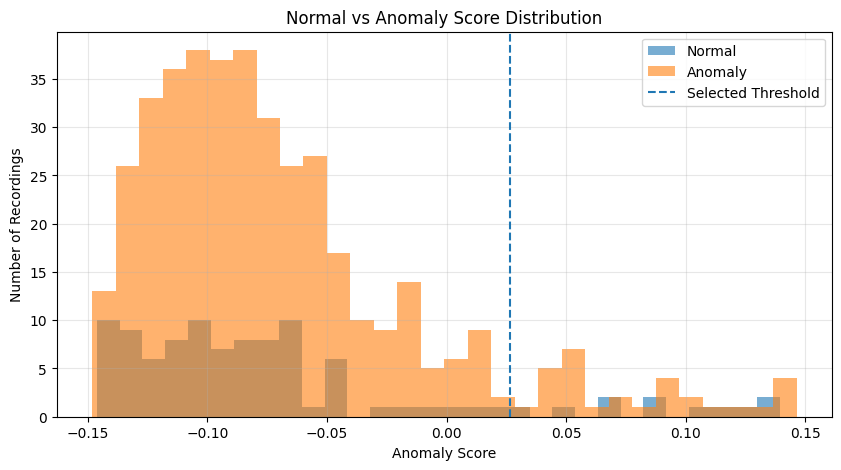

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    test_scores[y_test == 0],
    bins=30,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    test_scores[y_test == 1],
    bins=30,
    alpha=0.6,
    label="Anomaly"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Recordings")
plt.title("Normal vs Anomaly Score Distribution")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [13]:
# Inspect feature statistics
feature_statistics = X_train.describe().T

feature_statistics["range"] = (
    feature_statistics["max"] - feature_statistics["min"]
)

print("FEATURE STATISTICS")
print(
    feature_statistics[
        ["mean", "std", "min", "max", "range"]
    ].round(4).to_string()
)

FEATURE STATISTICS
                              mean       std        min        max      range
mfcc_1_mean              -278.7285   23.1752  -358.0509  -220.6799   137.3710
mfcc_2_mean                84.6492   21.7005    -0.4167   131.8621   132.2788
mfcc_3_mean                 3.2537   11.8795   -44.4706    44.5372    89.0078
mfcc_4_mean                18.8124   11.1427    -4.2838    38.8313    43.1151
mfcc_5_mean                 4.8809    5.7537   -11.4521    18.1435    29.5956
mfcc_6_mean                10.6967    5.6977    -3.4519    23.9265    27.3785
mfcc_7_mean                 1.6041    4.0988    -9.9382    12.9536    22.8918
mfcc_8_mean                 3.6869    3.1448    -8.1385    17.1704    25.3089
mfcc_9_mean                -1.0519    3.4025   -15.9976     8.7169    24.7145
mfcc_10_mean                3.0948    3.0588    -8.8450    15.8164    24.6615
mfcc_11_mean                0.2417    4.2778   -13.5231    13.6429    27.1659
mfcc_12_mean                2.7022    4.1073 

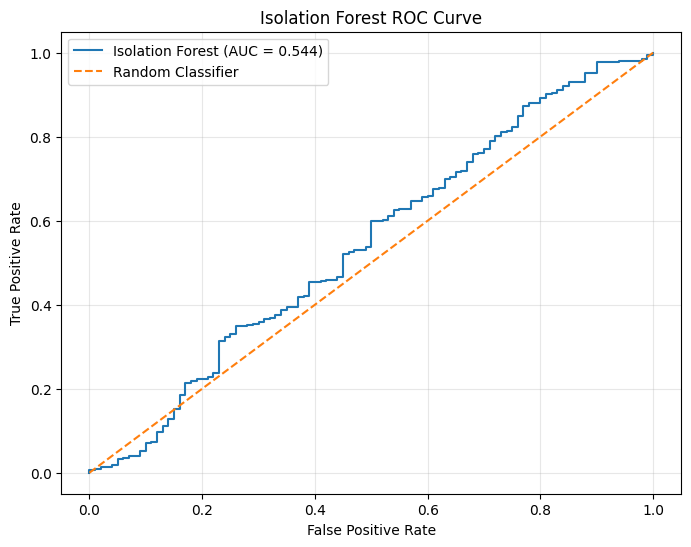

In [41]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Isolation Forest ROC curve
fpr_if, tpr_if, _ = roc_curve(y_test, test_scores)
auc_if = auc(fpr_if, tpr_if)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_if,
    tpr_if,
    label=f"Isolation Forest (AUC = {auc_if:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Isolation Forest ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(
    os.path.join(results_path, "IsolationForest_ROC_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [34]:

import os
import joblib
import json

# Define project folders
project_path = "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection"

models_path = os.path.join(project_path, "Models")
os.makedirs(models_path, exist_ok=True)

# Save Isolation Forest model
joblib.dump(
    model,
    os.path.join(models_path, "isolation_forest_model.pkl")
)

# Save Isolation Forest threshold and settings
metadata = {
    "selected_model": "Isolation Forest",
    "isolation_forest_threshold": float(threshold),
    "features": 34,
    "training_samples": 728,
    "validation_samples": 183,
    "test_samples": 507
}

with open(os.path.join(models_path, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)

print("Isolation Forest model saved successfully!")
print("Threshold:", threshold)
print("Models folder:", models_path)


Isolation Forest model saved successfully!
Threshold: 0.026746540350113694
Models folder: /content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection/Models


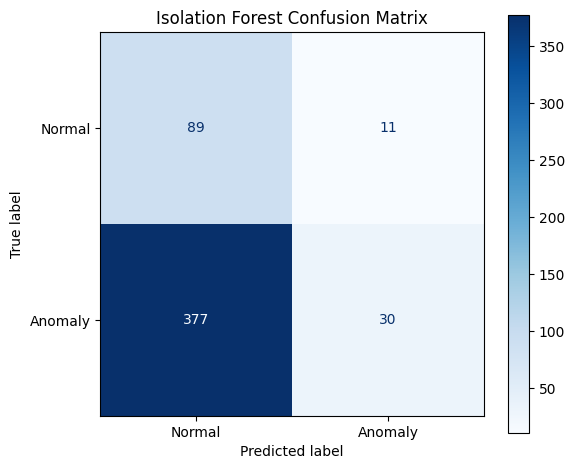

Isolation Forest confusion matrix saved successfully!


In [33]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Save Isolation Forest confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Anomaly"],
    ax=ax,
    cmap="Blues"
)

plt.title("Isolation Forest Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(results_path, "isolation_forest_confusion_matrix.png")
)

plt.show()

print("Isolation Forest confusion matrix saved successfully!")


In [20]:
import os

project_path = "/content/drive/MyDrive/Acoustic_Machine_Anomaly_Detection"

for folder in ["Feature_Extraction", "Processed_Datasets", "Models", "Results"]:
    folder_path = os.path.join(project_path, folder)

    print("\n" + "=" * 45)
    print(folder)

    if os.path.exists(folder_path):
        for file in sorted(os.listdir(folder_path)):
            print("  ", file)
    else:
        print("  Folder not found!")


Feature_Extraction
   Copy of extract_features.py
   Copy of feature_names.txt

Processed_Datasets
   X_test.csv
   X_train.csv
   X_validation.csv
   y_test.csv

Models
   isolation_forest_model.pkl
   model_metadata.json
   one_class_svm_model.pkl
   scaler.pkl

Results
   Copy of audio_inspection_report.csv
   isolation_forest_confusion_matrix.png
   model_comparison.csv
   one_class_svm_confusion_matrix.png
   roc_curve_comparison.png


In [21]:
import os

feature_path = os.path.join(project_path, "Feature_Extraction")
results_path = os.path.join(project_path, "Results")

files_to_rename = [
    (feature_path, "Copy of extract_features.py", "extract_features.py"),
    (feature_path, "Copy of feature_names.txt", "feature_names.txt"),
    (results_path, "Copy of audio_inspection_report.csv", "audio_inspection_report.csv")
]

for folder, old_name, new_name in files_to_rename:
    old_path = os.path.join(folder, old_name)
    new_path = os.path.join(folder, new_name)

    if os.path.exists(old_path):
        if not os.path.exists(new_path):
            os.rename(old_path, new_path)
            print("Renamed:", new_name)
        else:
            print("Already exists:", new_name)
    else:
        print("Original file not found:", old_name)

Renamed: extract_features.py
Renamed: feature_names.txt
Renamed: audio_inspection_report.csv


In [22]:
dataset_path = os.path.join(project_path, "Dataset")

print("DATASET FOLDER CHECK")

if os.path.exists(dataset_path):
    for item in sorted(os.listdir(dataset_path)):
        item_path = os.path.join(dataset_path, item)

        if os.path.isdir(item_path):
            print("[FOLDER]", item)
        else:
            print("[FILE]", item)
else:
    print("Dataset folder not found!")

DATASET FOLDER CHECK
[FILE] Copy of dev_data_fan.zip
[FOLDER] fan_data


In [23]:
old_path = os.path.join(dataset_path, "Copy of dev_data_fan.zip")
new_path = os.path.join(dataset_path, "dev_data_fan.zip")

if os.path.exists(old_path) and not os.path.exists(new_path):
    os.rename(old_path, new_path)
    print("Dataset ZIP renamed successfully!")
elif os.path.exists(new_path):
    print("Correct filename already exists!")
else:
    print("ZIP file not found!")

Dataset ZIP renamed successfully!


In [24]:
feature_file = os.path.join(
    project_path,
    "Feature_Extraction",
    "extract_features.py"
)

with open(feature_file, "r") as f:
    print(f.read())


def extract_features(audio, sr):

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    rms = librosa.feature.rms(y=audio)[0]
    rms_features = [np.mean(rms), np.std(rms)]

    zcr = librosa.feature.zero_crossing_rate(y=audio)[0]
    zcr_features = [np.mean(zcr), np.std(zcr)]

    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]
    centroid_features = [np.mean(centroid), np.std(centroid)]

    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )[0]
    bandwidth_features = [np.mean(bandwidth), np.std(bandwidth)]

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features,
        bandwidth_features
    ])

    return features



In [26]:
feature_code = '''
import numpy as np
import librosa

def extract_features(audio, sr):

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    rms = librosa.feature.rms(y=audio)[0]
    rms_features = [np.mean(rms), np.std(rms)]

    zcr = librosa.feature.zero_crossing_rate(y=audio)[0]
    zcr_features = [np.mean(zcr), np.std(zcr)]

    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]
    centroid_features = [np.mean(centroid), np.std(centroid)]

    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )[0]
    bandwidth_features = [np.mean(bandwidth), np.std(bandwidth)]

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features,
        bandwidth_features
    ])

    return features
'''

with open(feature_file, "w") as f:
    f.write(feature_code)

print("Feature extraction file updated successfully!")
print("Imports added: NumPy and Librosa")

Feature extraction file updated successfully!
Imports added: NumPy and Librosa


In [37]:
import joblib
import os

joblib.dump(
    threshold,
    os.path.join(models_path, "threshold_isolation_forest.pkl")
)

print("Threshold saved successfully!")

Threshold saved successfully!


In [39]:
import pandas as pd
import os

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, test_scores)
    ]
})

results.to_csv(
    os.path.join(results_path, "IsolationForest_Results.csv"),
    index=False
)

print("Results CSV saved successfully!")
display(results)

Results CSV saved successfully!


,Metric,Value
0,Accuracy,0.234714
1,Precision,0.731707
2,Recall,0.073710
3,F1-Score,0.133929
4,ROC-AUC,0.543636


In [40]:
import joblib
import os

joblib.dump(
    threshold,
    os.path.join(models_path, "threshold_isolation_forest.pkl")
)

print("Threshold file saved successfully!")

Threshold file saved successfully!
